In [240]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,id,image_path,label
0,P00001,img_00001.jpg,queen
1,P00002,img_00002.jpg,rook
2,P00003,img_00003.jpg,rook
3,P00004,img_00004.jpg,bishop
4,P00005,img_00005.jpg,queen


In [241]:
df_train.label.unique()

array(['queen', 'rook', 'bishop', 'knight', 'pawn'], dtype=object)

In [242]:
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_train.label = enc.fit_transform(df_train.label)
df_train.head()

,id,image_path,label
0,P00001,img_00001.jpg,3
1,P00002,img_00002.jpg,4
2,P00003,img_00003.jpg,4
3,P00004,img_00004.jpg,0
4,P00005,img_00005.jpg,3


(224, 224)


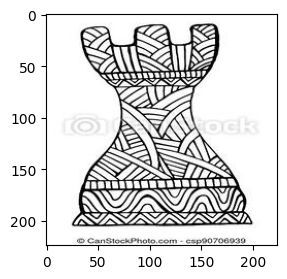

In [243]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("images/img_00003.jpg")

print(img.size)

plt.figure(figsize=(3, 3))
plt.imshow(img)

In [250]:
import torch

num_epochs = 14
batch_size = 32
learning_rate = 0.0003

device = torch.device("cuda")
device

device(type='cuda')

In [251]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import cv2

train_transforms = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(0.2, 0.2, 0.2, 0.1),
    T.RandomRotation(10),
    T.ToTensor(),
])

valid_transforms = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
])

class MyDataset(Dataset):
    def __init__(self, df, transforms, img_size=128):
        self.df = df
        self.transforms = transforms
        self.img_size = img_size
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = f'images/{self.df.image_path.iloc[idx]}'
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = self.transforms(img)
        label = torch.tensor(self.df.label.iloc[idx], dtype=torch.int64)
        return img, label

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.2, random_state=42)

train_dataset = MyDataset(df_1, train_transforms)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

valid_dataset = MyDataset(df_2, valid_transforms)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size)

In [252]:
train_dataset[0][0][0][0][0]

tensor(0.)

In [253]:
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.MaxPool2d(2, 2),
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.MaxPool2d(2, 2),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.MaxPool2d(2, 2),
            nn.ReLU(),

            nn.Flatten(),
            nn.LazyLinear(64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 5)
        )
    def forward(self, X):
        X = self.net(X)
        return X

model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

model

CNN(
  (net): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ReLU()
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): ReLU()
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): ReLU()
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): LazyLinear(in_features=0, out_features=64, bias=True)
    (11): ReLU()
    (12): Linear(in_features=64, out_features=32, bias=True)
    (13): ReLU()
    (14): Linear(in_features=32, out_features=5, bias=True)
  )
)

In [254]:
def train(model, device, train_loader, criterion, optimizer, epoch):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f'Epoch {epoch}')
    print(f'Training Loss {total_loss/len(train_loader)}')
def test(model, device, test_loader, criterion):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            loss = criterion(model(inputs), labels)
            total_loss += loss.item()
    print(f'Validation Loss {total_loss/len(test_loader)}')

In [255]:
for epoch in range(1, num_epochs+1):
    train(model, device, train_loader, criterion, optimizer, epoch)
    test(model, device, valid_loader, criterion)

Epoch 1
Training Loss 1.5870896852933443
Validation Loss 1.5959851741790771
Epoch 2
Training Loss 1.5825979159428523
Validation Loss 1.588842660188675
Epoch 3
Training Loss 1.5792859701009898
Validation Loss 1.5863456726074219
Epoch 4
Training Loss 1.5638469182527983
Validation Loss 1.5711911916732788
Epoch 5
Training Loss 1.5490176310906043
Validation Loss 1.5600851476192474
Epoch 6
Training Loss 1.5162987158848689
Validation Loss 1.5314602255821228
Epoch 7
Training Loss 1.4808532366385827
Validation Loss 1.4625319242477417
Epoch 8
Training Loss 1.421053226177509
Validation Loss 1.3670534193515778
Epoch 9
Training Loss 1.343278692318843
Validation Loss 1.3159478604793549
Epoch 10
Training Loss 1.3320478017513568
Validation Loss 1.3093148469924927
Epoch 11
Training Loss 1.257620252095736
Validation Loss 1.285401850938797
Epoch 12
Training Loss 1.2450035076874952
Validation Loss 1.1690352857112885
Epoch 13
Training Loss 1.1927633468921368
Validation Loss 1.1813959032297134
Epoch 14
Trai

In [262]:
final_transforms = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
])

class FinalDataset(Dataset):
    def __init__(self, df, transforms, img_size=128):
        self.df = df
        self.transforms = transforms
        self.img_size = img_size
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = f'images/{self.df.image_path.iloc[idx]}'
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = self.transforms(img)
        return img

final_dataset = FinalDataset(df_test, final_transforms)
final_loader = DataLoader(final_dataset, batch_size=batch_size)

In [263]:
final_dataset[0][0][0][0]

tensor(0.3333)

In [264]:
model.eval()
preds = []

with torch.no_grad():
    for inputs in final_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        output = torch.argmax(outputs, dim=1).cpu().numpy()
        preds.extend(output)

preds[:10]

[0, 4, 1, 1, 0, 4, 0, 0, 1, 1]

In [265]:
preds = enc.inverse_transform(preds)
preds[:10]

array(['bishop', 'rook', 'knight', 'knight', 'bishop', 'rook', 'bishop',
       'bishop', 'knight', 'knight'], dtype=object)

In [266]:
submission = pd.DataFrame({
    "id": df_test.id,
    "label": preds
})

submission

,id,label
0,P00521,bishop
1,P00522,rook
2,P00523,knight
3,P00524,knight
4,P00525,bishop
...,...,...
126,P00647,bishop
127,P00648,rook
128,P00649,knight
129,P00650,knight


In [267]:
submission.to_csv("submission.csv", index=False)